# After the timeout: a matched Spurs review

Joseph Smarrelli · September 2026 · 2025–26 regular season

The Spurs improved from a negative scoring margin in the minute before a timeout to a positive margin in the minute after it. A matched group of situations without an immediate timeout improved too. The rebound by itself is therefore weak evidence that the timeout changed the next minute.

This study asks a narrow question: after an opponent’s made field goal, how did San Antonio’s next minute compare with similar moments in the same game when neither team immediately called a timeout?



In [1]:
from pathlib import Path
import os, sys
root = Path.cwd()
if root.name == 'notebooks':
    root = root.parent
sys.path.insert(0, str(root))
os.chdir(root)
import pandas as pd
from IPython.display import display, Image
from src import timeout_reset
summary = timeout_reset.run()
from src import figures
figures.run()
summary

{'eligible_timeouts': 144,
 'matched_timeouts': 43,
 'matched_games': 33,
 'unique_controls': 57,
 'matched_difference': -0.5426356589147286,
 'lower': -1.2523648648648646,
 'upper': 0.15980525362318798,
 'change_difference': -0.5426356589147286,
 'change_lower': -1.2523648648648646,
 'change_upper': 0.15980525362318798,
 'later_timeout_treated_share': np.float64(0.06976744186046512),
 'later_timeout_control_share': np.float64(0.26356589147286824),
 'trajectories': [{'group': 'treated',
   'phase': 'pre',
   'net': -1.9767441860465116,
   'lower': -2.442063953488372,
   'upper': -1.4772456709956712},
  {'group': 'treated',
   'phase': 'post',
   'net': 0.7441860465116279,
   'lower': 0.04878048780487805,
   'upper': 1.408186456400742},
  {'group': 'control',
   'phase': 'pre',
   'net': -1.9767441860465116,
   'lower': -2.442063953488372,
   'upper': -1.4772456709956712},
  {'group': 'control',
   'phase': 'post',
   'net': 1.2868217054263567,
   'lower': 0.7587510442773601,
   'upper'

## Results
The following table is regenerated from the pinned inputs.

In [2]:
pd.read_csv('results/timeout_sensitivity.csv')

,pre_caliper,timeouts,games,estimate,lower,upper,pre_difference
0,0,43,33,-0.542636,-1.252365,0.159805,0.000000
1,1,82,49,-0.302846,-0.975612,0.341258,-0.067073
2,2,107,56,-0.490654,-1.007640,0.020263,-0.341121


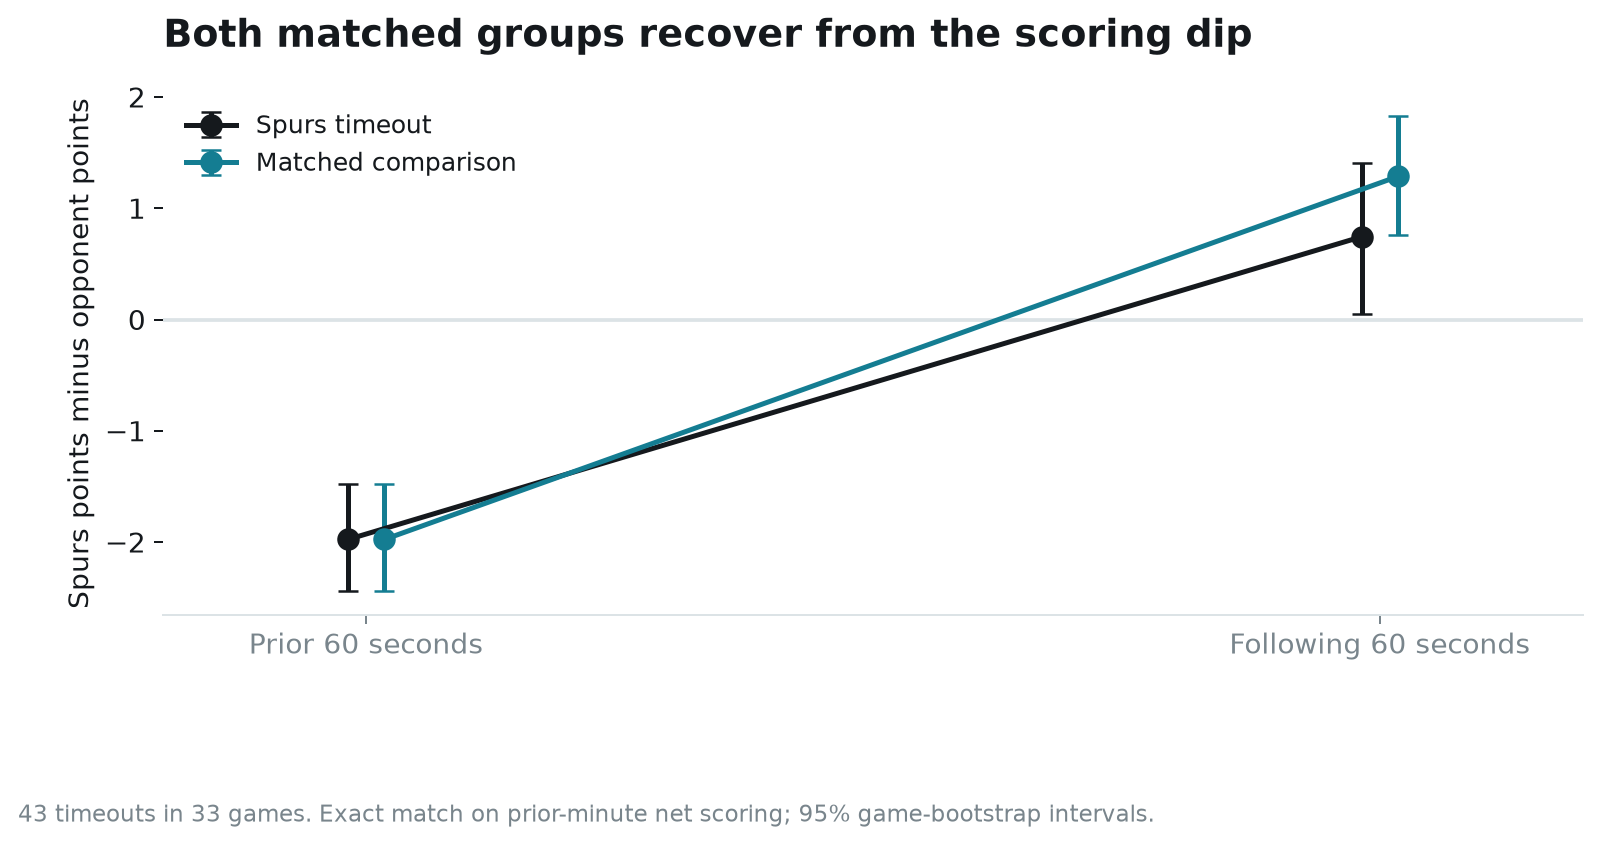

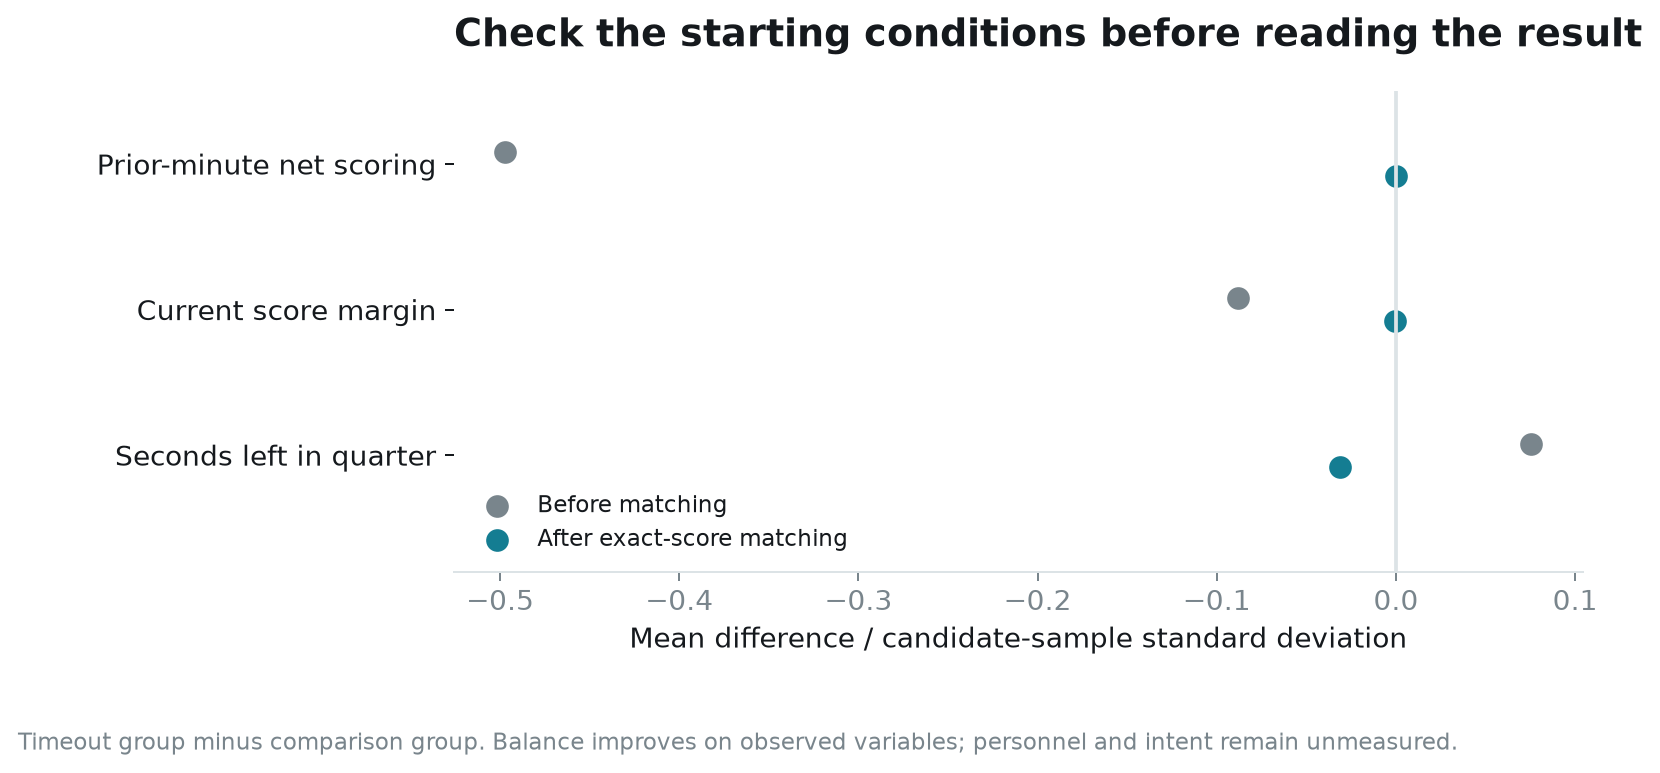

In [3]:
display(Image(filename='figures/timeout_rebound.png'))
display(Image(filename='figures/timeout_balance.png'))

## Recalculate the matched comparison
Each timeout has equal total weight, regardless of how many controls it has.

In [4]:
import numpy as np
pairs = pd.read_csv('results/timeout_pairs.csv')
assert np.allclose(pairs.groupby(['game_id','event_id']).weight.sum(), 1)
assert (pairs.treated_pre_net == pairs.control_pre_net).all()
effect = pairs.assign(difference=pairs.weight*(pairs.treated_post_net-pairs.control_post_net)).groupby(['game_id','event_id']).difference.sum().mean()
display(effect)
display(pd.read_csv('results/timeout_match_audit.csv').controls.value_counts().sort_index())
display(pd.read_csv('results/timeout_balance.csv'))

np.float64(-0.5426356589147288)

controls
0    101
1     31
2     10
3      2
Name: count, dtype: int64

,variable,before,after
0,pre_net,-0.497051,0.000000
1,margin,-0.088245,-0.000708
2,seconds,0.075570,-0.031342


## Interpretation and limits
Read the complete accompanying article for denominators, uncertainty, model selection, and the basketball decisions this analysis cannot identify. The results here are historical research, not a claim of team deployment.